In [ ]:
import time

# Start timer
start_time = time.perf_counter()

In [ ]:
pip install tensorflow matplotlib scikit-image

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Cropping2D
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt

def build_denoising_autoencoder():
    input_img = Input(shape=(500, 500, 1))  # Match loaded image size

    # Encoder
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    #Final output layer reduces channels to 1
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    autoencoder = Model(input_img, decoded) # Changed to use 'decoded' as output
    return autoencoder

In [ ]:
import numpy as np
from skimage.util import random_noise

def add_noise(images):
    noisy = []
    for img in images:
        noisy_img = random_noise(img, mode='gaussian', var=0.01)
        noisy.append(noisy_img)
    return np.array(noisy)

In [ ]:
!pip install opencv-python

In [ ]:
!pip install tensorflow matplotlib scikit-image opencv-python

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Cropping2D

def build_autoencoder(input_shape):
    input_img = Input(shape=input_shape)

    # Encoder
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    # Reverted padding to 'same' and added Cropping2D to match input_shape
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    # Calculate cropping amounts
    # The output shape before cropping might be slightly larger than input_shape
    # We need to calculate how much to crop from top/bottom and left/right
    output_h, output_w = tf.keras.backend.int_shape(decoded)[1:3]
    input_h, input_w = input_shape[0:2]

    crop_h_top = (output_h - input_h) // 2
    crop_h_bottom = output_h - input_h - crop_h_top
    crop_w_left = (output_w - input_w) // 2
    crop_w_right = output_w - input_w - crop_w_left

    # Ensure cropping amounts are non-negative
    crop_h_top = max(0, crop_h_top)
    crop_h_bottom = max(0, crop_h_bottom)
    crop_w_left = max(0, crop_w_left)
    crop_w_right = max(0, crop_w_right)


    cropped_decoded = Cropping2D(cropping=((crop_h_top, crop_h_bottom), (crop_w_left, crop_w_right)))(decoded)


    autoencoder = Model(input_img, cropped_decoded) # Use the cropped output
    autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

    return autoencoder

In [ ]:
import cv2

def sharpen_image(image):
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=1)
    sharpened = cv2.addWeighted(image, 1.5, blurred, -0.5, 0)
    return sharpened

def combined_loss(y_true, y_pred):
    ssim = 1 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    edge_true = tf.image.sobel_edges(y_true)
    edge_pred = tf.image.sobel_edges(y_pred)
    edge_loss = tf.reduce_mean(tf.abs(edge_true - edge_pred))
    return ssim + 0.5 * edge_loss

In [ ]:
import torch
import torch.nn as nn

class LineAutoencoder(nn.Module):
    def __init__(self):
        super(LineAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # H/2
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # H/4

        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 2, stride=2), nn.ReLU(),  # H/2
            nn.ConvTranspose2d(32, 1, 2, stride=2), nn.Sigmoid()  # H
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms as T

class LineCorrectionDataset(Dataset):
    def __init__(self, bad_dir, good_dir, image_size=(256, 256)):
        self.bad_dir = bad_dir
        self.good_dir = good_dir
        self.files = sorted(os.listdir(bad_dir))
        self.transform = T.Compose([
            T.Grayscale(),
            T.Resize(image_size),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        bad_filename = self.files[idx]
        # Assuming good filenames are 'G' + bad filename (excluding extension) + extension
        name, ext = os.path.splitext(bad_filename)
        good_filename = f"G{name}{ext}"

        bad_path = os.path.join(self.bad_dir, bad_filename)
        good_path = os.path.join(self.good_dir, good_filename)

        bad = self.transform(Image.open(bad_path).convert("RGB"))
        good = self.transform(Image.open(good_path).convert("RGB"))
        return bad, good

In [ ]:
!pip install opencv-python

In [ ]:
# Mount Google Drive if running in Google Colab, otherwise use local repository paths
import os
try:
    from google.colab import drive
    if not os.path.exists('../data') and not os.path.exists('data'):
        drive.mount('/content/drive', force_remount=True)
except ImportError:
    pass


Mounted at /content/drive


Epoch 1/20, Loss: 1.363444
Epoch 2/20, Loss: 1.224526
Epoch 3/20, Loss: 1.033554
Epoch 4/20, Loss: 0.800372
Epoch 5/20, Loss: 0.462795
Epoch 6/20, Loss: 0.323691
Epoch 7/20, Loss: 0.260955
Epoch 8/20, Loss: 0.214358
Epoch 9/20, Loss: 0.188138
Epoch 10/20, Loss: 0.164271
Epoch 11/20, Loss: 0.147365
Epoch 12/20, Loss: 0.134180
Epoch 13/20, Loss: 0.121809
Epoch 14/20, Loss: 0.110359
Epoch 15/20, Loss: 0.100834
Epoch 16/20, Loss: 0.091995
Epoch 17/20, Loss: 0.082820
Epoch 18/20, Loss: 0.074009
Epoch 19/20, Loss: 0.066054
Epoch 20/20, Loss: 0.058937
Applying autoencoder to images in: /content/drive/MyDrive/Bad Images
Processed 12.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_12.png
Original Image (12.png):


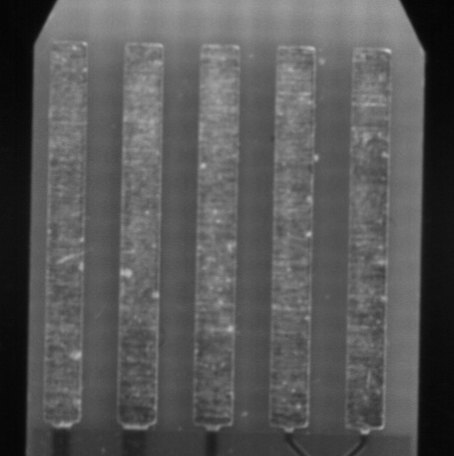

Autoencoder Corrected Output (12.png):


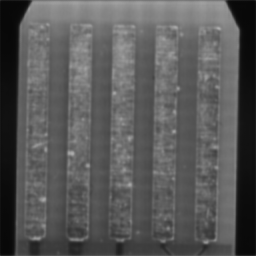

Processed 14.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_14.png
Original Image (14.png):


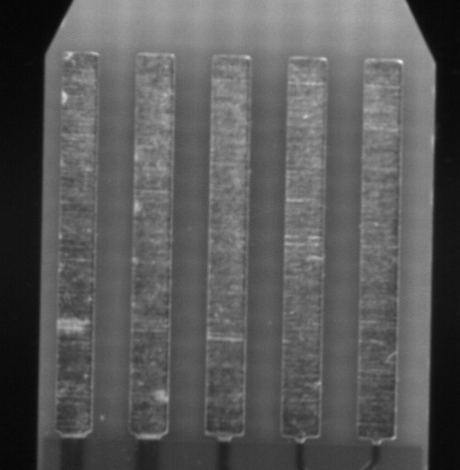

Autoencoder Corrected Output (14.png):


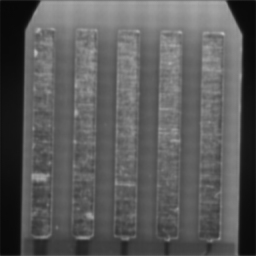

Processed 10.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_10.png
Original Image (10.png):


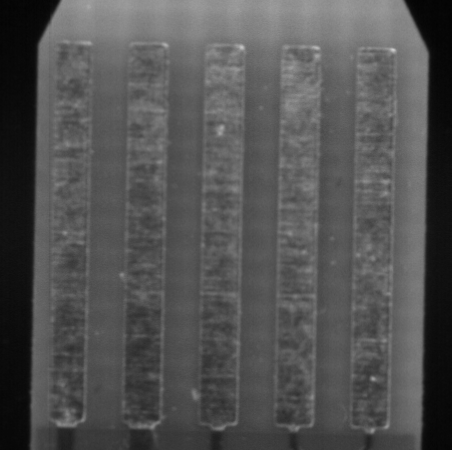

Autoencoder Corrected Output (10.png):


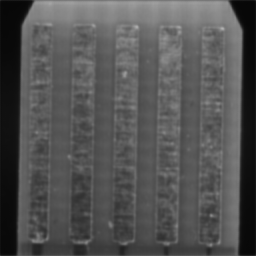

Processed 15.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_15.png
Original Image (15.png):


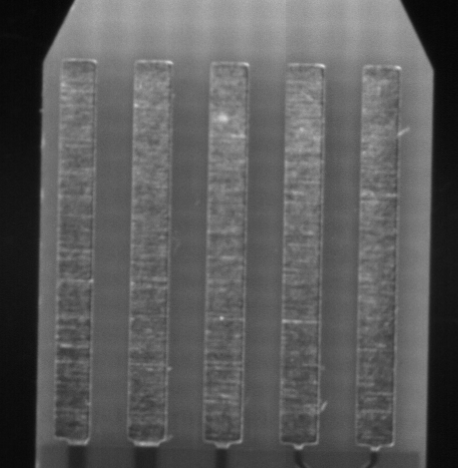

Autoencoder Corrected Output (15.png):


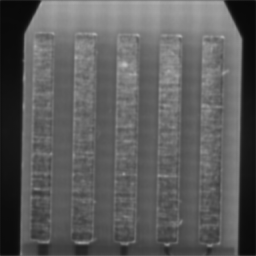

Processed 11.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_11.png
Original Image (11.png):


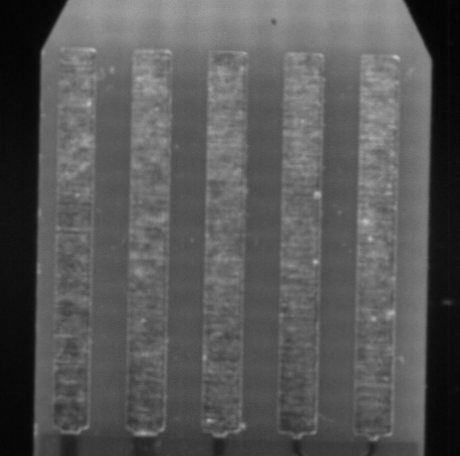

Autoencoder Corrected Output (11.png):


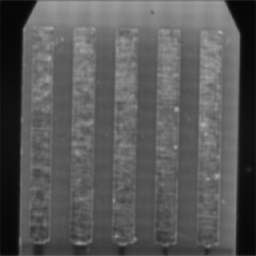

Processed 17.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_17.png
Original Image (17.png):


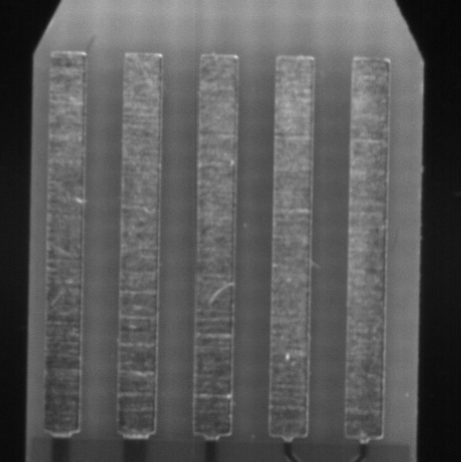

Autoencoder Corrected Output (17.png):


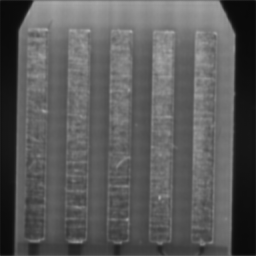

Processed 16.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_16.png
Original Image (16.png):


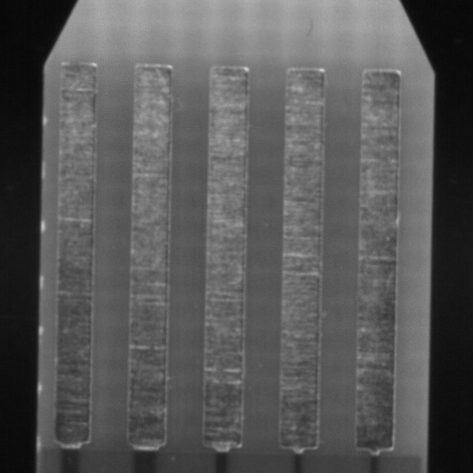

Autoencoder Corrected Output (16.png):


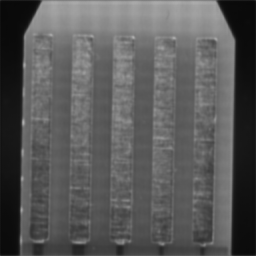

Processed 3.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_3.png
Original Image (3.png):


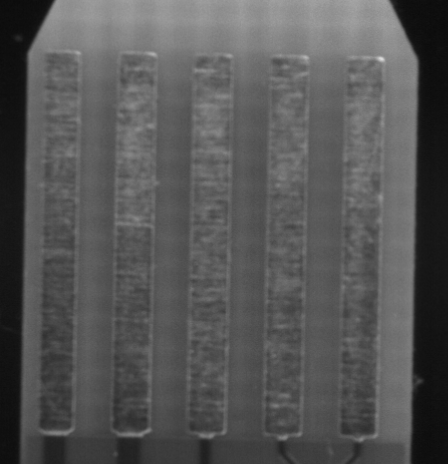

Autoencoder Corrected Output (3.png):


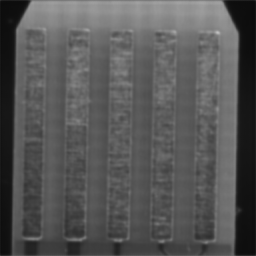

Processed 4.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_4.png
Original Image (4.png):


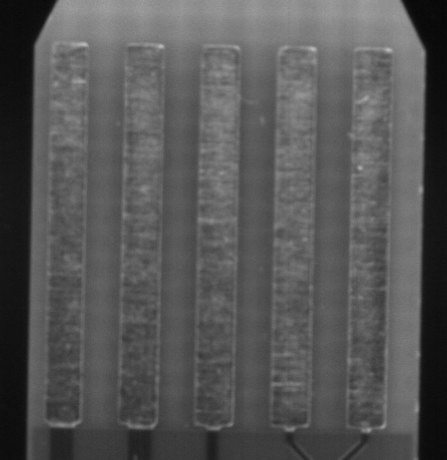

Autoencoder Corrected Output (4.png):


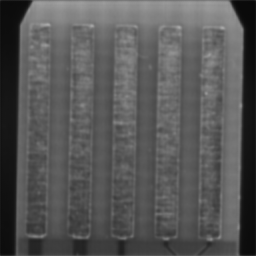

Processed 13.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_13.png
Original Image (13.png):


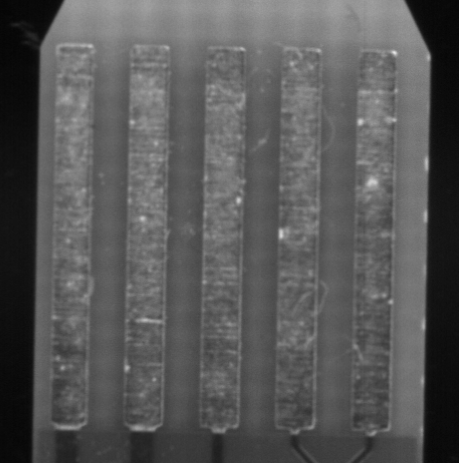

Autoencoder Corrected Output (13.png):


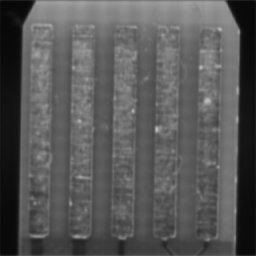

Processed 20.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_20.png
Original Image (20.png):


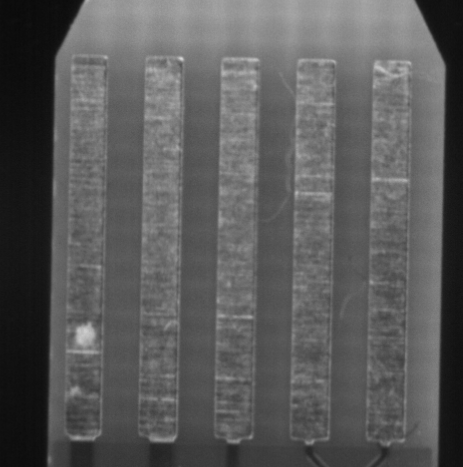

Autoencoder Corrected Output (20.png):


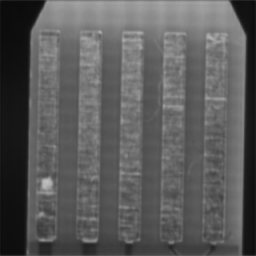

Processed 19.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_19.png
Original Image (19.png):


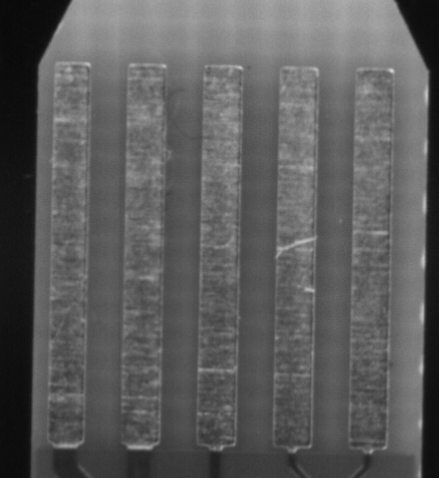

Autoencoder Corrected Output (19.png):


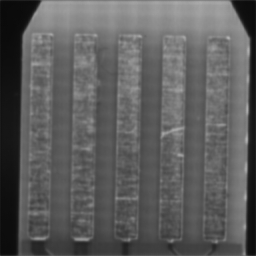

Processed 18.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_18.png
Original Image (18.png):


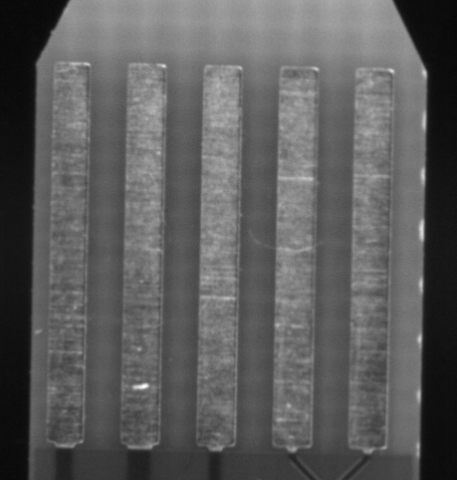

Autoencoder Corrected Output (18.png):


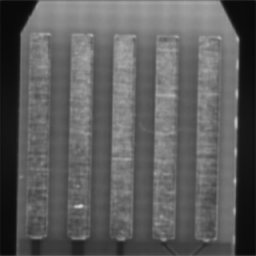

Processed 5.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_5.png
Original Image (5.png):


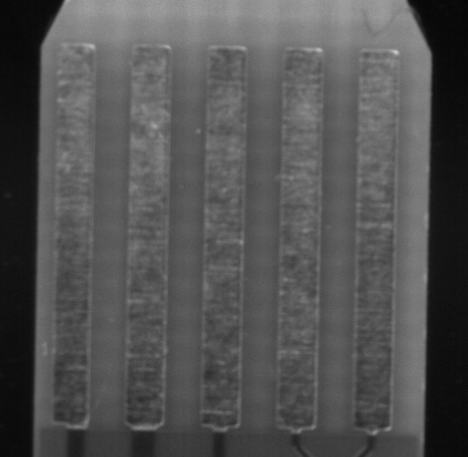

Autoencoder Corrected Output (5.png):


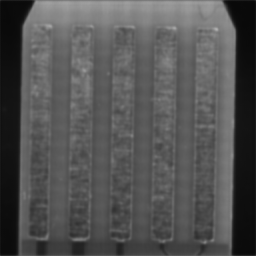

Processed 2.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_2.png
Original Image (2.png):


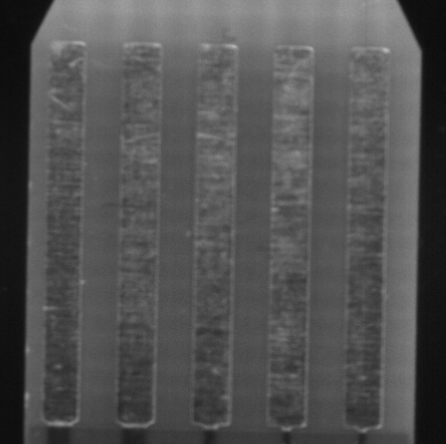

Autoencoder Corrected Output (2.png):


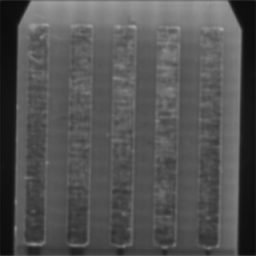

Processed 1.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_1.png
Original Image (1.png):


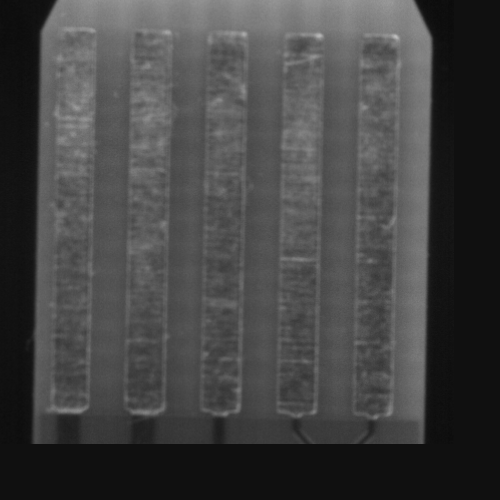

Autoencoder Corrected Output (1.png):


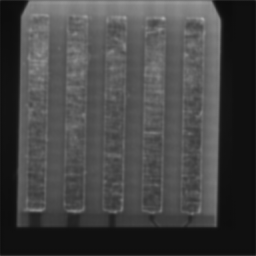

Processed 8.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_8.png
Original Image (8.png):


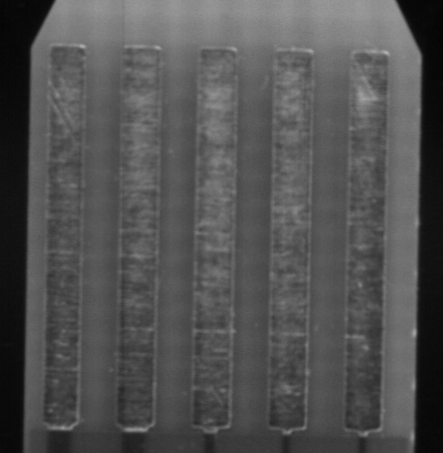

Autoencoder Corrected Output (8.png):


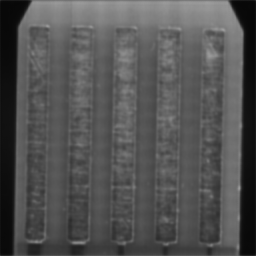

Processed 9.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_9.png
Original Image (9.png):


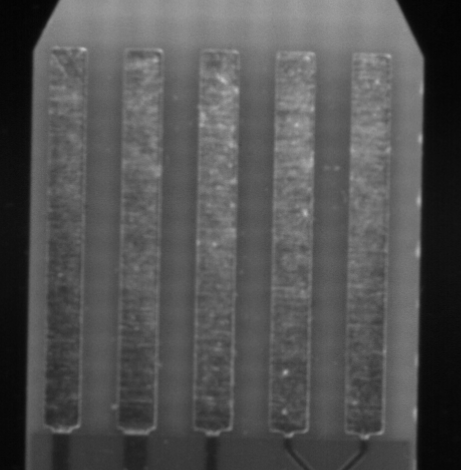

Autoencoder Corrected Output (9.png):


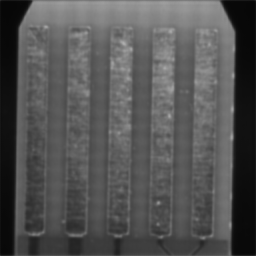

Processed 6.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_6.png
Original Image (6.png):


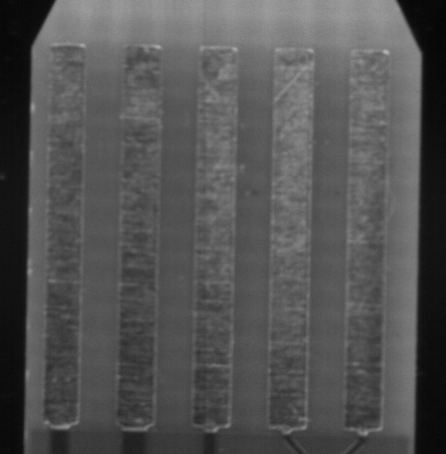

Autoencoder Corrected Output (6.png):


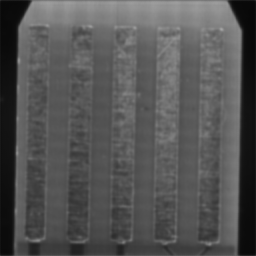

Processed 7.png and saved corrected image to /content/drive/MyDrive/bad_images_new_folder/corrected_7.png
Original Image (7.png):


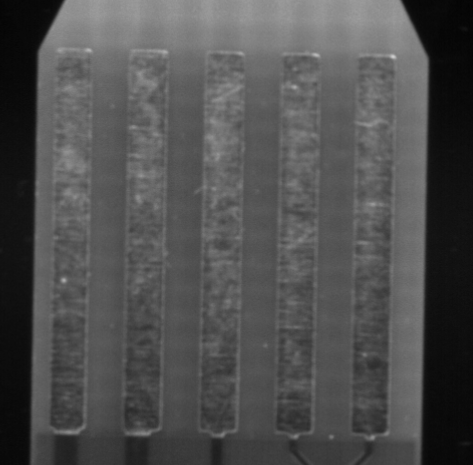

Autoencoder Corrected Output (7.png):


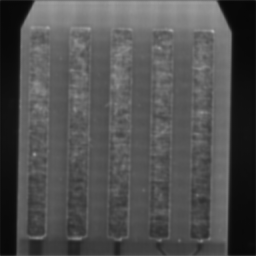

Autoencoder processing complete for all images.


In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as T
from PIL import Image
from google.colab.patches import cv2_imshow
from torch.utils.data import Dataset, DataLoader
from math import exp


# Corrected SSIM implementation
def gaussian(window_size, sigma):
    gauss = torch.Tensor([exp(-(x - window_size//2)**2/float(2*sigma**2)) for x in range(window_size)])
    return gauss/gauss.sum()

def create_window(window_size, channel=1):
    _1D_window = gaussian(window_size, 1.5).unsqueeze(1)
    _2D_window = _1D_window.mm(_1D_window.t()).float().unsqueeze(0).unsqueeze(0)
    window = _2D_window.expand(channel, 1, window_size, window_size).contiguous()
    return window

def ssim(img1, img2, window_size=11, window=None, size_average=True, full=False, val_range=None):
    if val_range is None:
        if torch.max(img1) > 128:
            max_val = 255
        else:
            max_val = 1
        if torch.min(img1) < -0.5:
            min_val = -1
        else:
            min_val = 0
        L = max_val - min_val
    else:
        L = val_range

    padd = window_size // 2
    (_, channel, height, width) = img1.size()
    if window is None:
        real_size = min(window_size, height, width)
        window = create_window(real_size, channel=channel).to(img1.device)

    mu1 = F.conv2d(img1, window, padding=padd, groups=channel)
    mu2 = F.conv2d(img2, window, padding=padd, groups=channel)
    mu1_sq = mu1.pow(2)
    mu2_sq = mu2.pow(2)
    mu1_mu2 = mu1 * mu2
    sigma1_sq = F.conv2d(img1 * img1, window, padding=padd, groups=channel) - mu1_sq
    sigma2_sq = F.conv2d(img2 * img2, window, padding=padd, groups=channel) - mu2_sq
    sigma12 = F.conv2d(img1 * img2, window, padding=padd, groups=channel) - mu1_mu2

    C1 = (0.01 * L) ** 2
    C2 = (0.03 * L) ** 2

    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))

    if size_average:
        return ssim_map.mean()
    else:
        return ssim_map.mean(1).mean(1).mean(1)


class ImageDataset(Dataset):
    def __init__(self, image_dir, image_size=(256, 256)):
        self.image_dir = image_dir
        self.files = sorted(os.listdir(image_dir))
        self.transform = T.Compose([
            T.Grayscale(),
            T.Resize(image_size),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filename = self.files[idx]
        image_path = os.path.join(self.image_dir, filename)
        image = self.transform(Image.open(image_path).convert("RGB"))
        return image, image


class LineAutoencoder(nn.Module):
    def __init__(self):
        super(LineAutoencoder, self).__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)  # 128x128
        self.enc2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)  # 64x64

        # Decoder
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)  # 128x128
        self.dec1 = nn.Sequential(nn.Conv2d(96, 32, 3, padding=1), nn.ReLU())  # Adjusted for skip connection
        self.up2 = nn.ConvTranspose2d(32, 16, 2, stride=2)  # 256x256
        self.dec2 = nn.Sequential(nn.Conv2d(48, 1, 3, padding=1), nn.Sigmoid()) # Adjusted for skip connection

    def forward(self, x):
        x1 = self.enc1(x)         # 32x256x256
        x2 = self.pool1(x1)       # 32x128x128
        x3 = self.enc2(x2)        # 64x128x128
        x4 = self.pool2(x3)       # 64x64x64

        x = self.up1(x4)          # 32x128x128
        x = self.dec1(torch.cat([x, x3], dim=1))  # concat skip

        x = self.up2(x)           # 16x256x256
        x = self.dec2(torch.cat([x, x1], dim=1))  # concat skip
        return x

# Define the folder containing the input images
input_folder = '../data/raw/bad_images' if os.path.exists('../data/raw/bad_images') else ('data/raw/bad_images' if os.path.exists('data/raw/bad_images') else '/content/drive/MyDrive/Bad Images')
autoencoder_output_folder = '../data/processed/corrected_bad' if os.path.exists('../data/processed') else ('data/processed/corrected_bad' if os.path.exists('data/processed') else '/content/drive/MyDrive/bad_images_new_folder')
good_dir = "../data/raw/good_images" if os.path.exists("../data/raw/good_images") else ("data/raw/good_images" if os.path.exists("data/raw/good_images") else "/content/drive/MyDrive/Good Images")

# Create output folder for autoencoder results if it doesn't exist
os.makedirs(autoencoder_output_folder, exist_ok=True)

# Define the same transformations used for training the autoencoder
transform = T.Compose([
    T.Grayscale(),
    T.Resize((256, 256)), # Make sure this matches the training size
    T.ToTensor()
])

def hybrid_loss(pred, target):
    mse = nn.MSELoss()(pred, target)
    ssim_loss = 1 - ssim(pred, target) # Use the corrected local ssim function
    return 0.5 * mse + 0.5 * ssim_loss

def apply_clahe_to_autoencoder_output(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    return enhanced


dataset = ImageDataset(good_dir)
loader = DataLoader(dataset, batch_size=4, shuffle=True)

# 6. Train the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = LineAutoencoder().to(device)
criterion = hybrid_loss
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 20
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for images, _ in loader:
        images = images.to(device)

        output = model(images)
        loss = criterion(output, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss:.6f}")


# Set the model to evaluation mode
model.eval()

print(f"Applying autoencoder to images in: {input_folder}")

# Get a list of image files in the input folder
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# Process each image
for image_file in image_files:
    image_path = os.path.join(input_folder, image_file)
    autoencoder_output_path = os.path.join(autoencoder_output_folder, f"corrected_{image_file}") # Save with a prefix

    # Read the image
    image = Image.open(image_path).convert("RGB")

    # Apply transformations and add batch dimension
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Pass the image through the trained autoencoder
    with torch.no_grad():
        corrected_image_tensor = model(image_tensor)

    # Postprocess the output tensor to a displayable image format
    corrected_image_tensor = corrected_image_tensor.squeeze(0).cpu() # Remove batch dimension and move to CPU
    corrected_image_numpy = corrected_image_tensor.mul(255).byte().numpy() # Scale to 0-255 and convert to numpy array
    corrected_image_numpy = np.transpose(corrected_image_numpy, (1, 2, 0)) # Change tensor format (C, H, W) to numpy format (H, W, C)
    corrected_image_numpy = cv2.cvtColor(corrected_image_numpy, cv2.COLOR_GRAY2BGR) # Convert grayscale to BGR for cv2_imshow

    enhanced_image = apply_clahe_to_autoencoder_output(corrected_image_numpy)
    cv2.imwrite(autoencoder_output_path, enhanced_image)

    # Save the corrected image
    #cv2.imwrite(autoencoder_output_path, corrected_image_numpy)

    print(f"Processed {image_file} and saved corrected image to {autoencoder_output_path}")

    # Display the original image and the autoencoder corrected image (optional, can be removed for large datasets)
    print(f"Original Image ({image_file}):")
    cv2_imshow(cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR))

    print(f"Autoencoder Corrected Output ({image_file}):")
    cv2_imshow(corrected_image_numpy)

print("Autoencoder processing complete for all images.")


In [ ]:
# Step 1: Import necessary libraries
import cv2
import matplotlib.pyplot as plt
from google.colab import files
import numpy as np

In [ ]:
!pip install pytorch-ssim

  Preparing metadata (setup.py) ... done
  Created wheel for pytorch-ssim: filename=pytorch_ssim-0.1-py3-none-any.whl size=2006 sha256=caaded7d31602f0fa0dbf4e6700836a46be086c5f2f26bed65aa5ec91936b951
  Stored in directory: /root/.cache/pip/wheels/54/a0/11/99f86224e71729ed9ef0c4ffe1b795807ad5f44bde19bc66f9
Successfully built pytorch-ssim


Epoch 1/20, Loss: 0.282470
Epoch 2/20, Loss: 0.255895
Epoch 3/20, Loss: 0.220046
Epoch 4/20, Loss: 0.165581
Epoch 5/20, Loss: 0.094504
Epoch 6/20, Loss: 0.087595
Epoch 7/20, Loss: 0.069504
Epoch 8/20, Loss: 0.059937
Epoch 9/20, Loss: 0.052276
Epoch 10/20, Loss: 0.042109
Epoch 11/20, Loss: 0.035631
Epoch 12/20, Loss: 0.028369
Epoch 13/20, Loss: 0.023262
Epoch 14/20, Loss: 0.019574
Epoch 15/20, Loss: 0.016707
Epoch 16/20, Loss: 0.014506
Epoch 17/20, Loss: 0.012533
Epoch 18/20, Loss: 0.011052
Epoch 19/20, Loss: 0.009780
Epoch 20/20, Loss: 0.008991
Applying autoencoder to images in: /content/drive/MyDrive/Good Images
Processed G20.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G20.png
Original Image (G20.png):


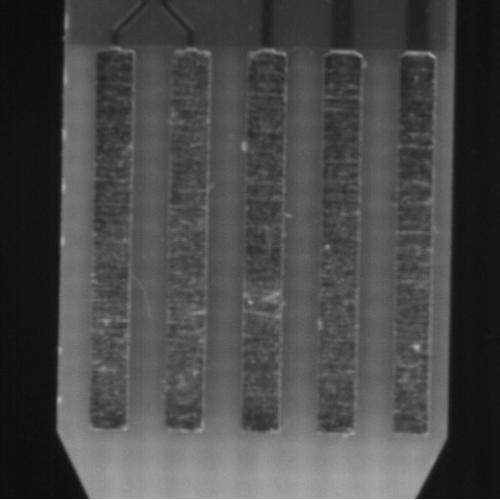

Autoencoder Corrected Output (G20.png):


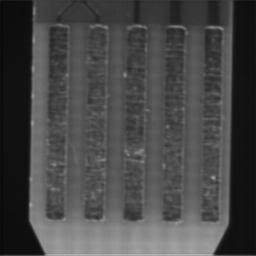

Processed G10.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G10.png
Original Image (G10.png):


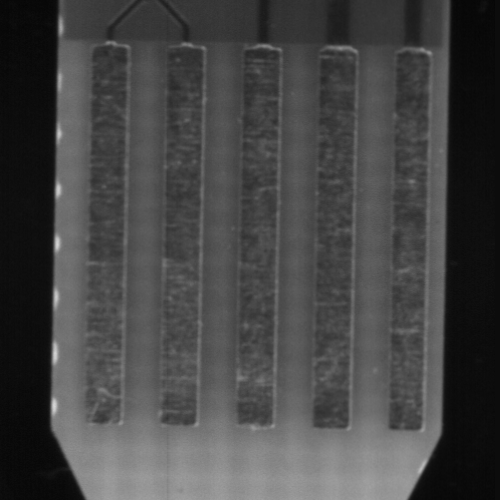

Autoencoder Corrected Output (G10.png):


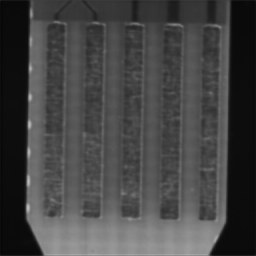

Processed G18.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G18.png
Original Image (G18.png):


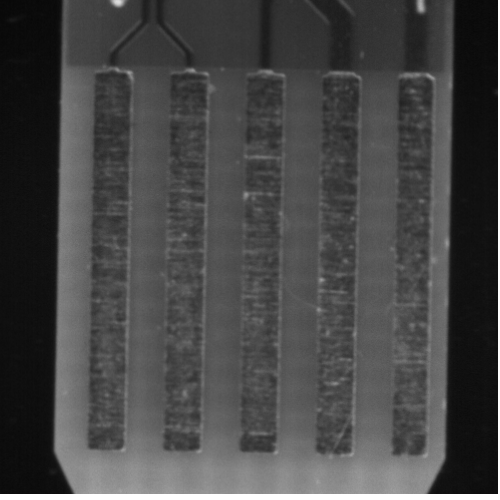

Autoencoder Corrected Output (G18.png):


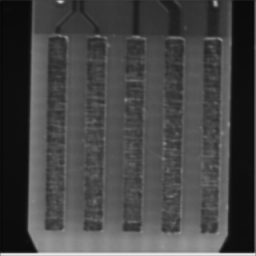

Processed G6.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G6.png
Original Image (G6.png):


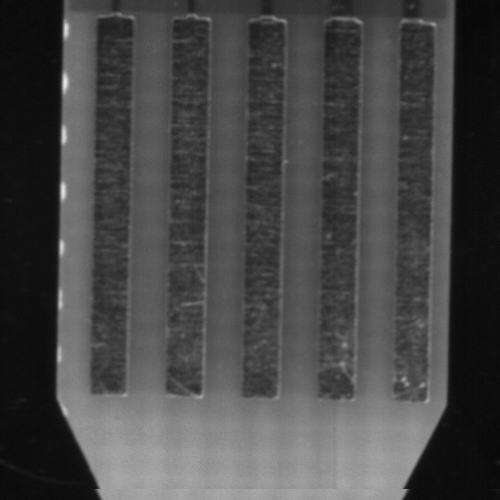

Autoencoder Corrected Output (G6.png):


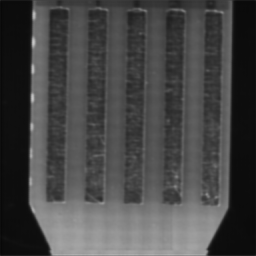

Processed G3.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G3.png
Original Image (G3.png):


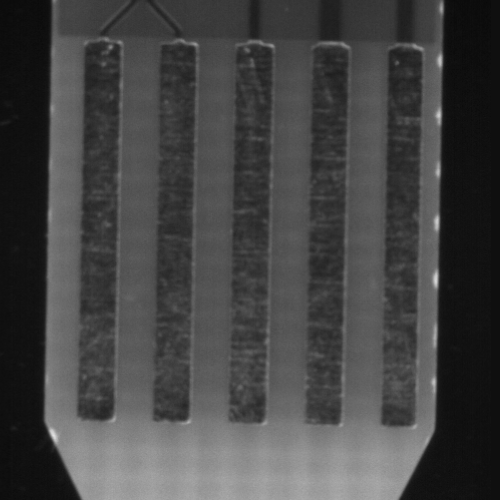

Autoencoder Corrected Output (G3.png):


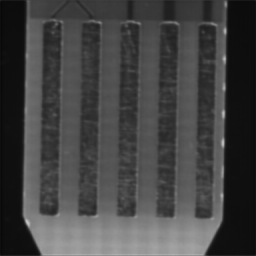

Processed G5.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G5.png
Original Image (G5.png):


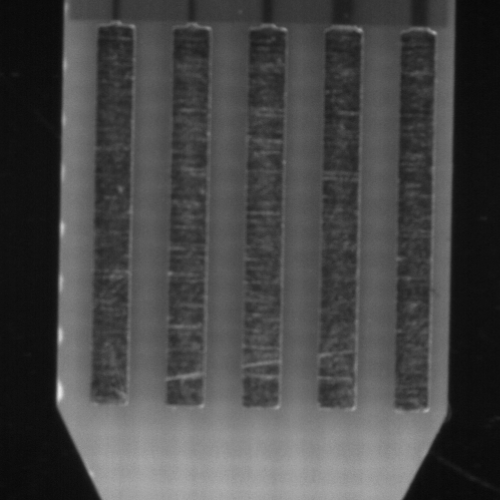

Autoencoder Corrected Output (G5.png):


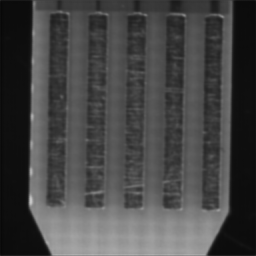

Processed G17.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G17.png
Original Image (G17.png):


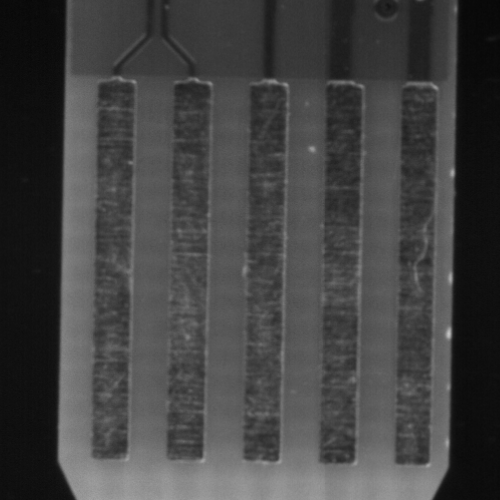

Autoencoder Corrected Output (G17.png):


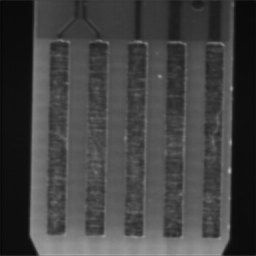

Processed G15.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G15.png
Original Image (G15.png):


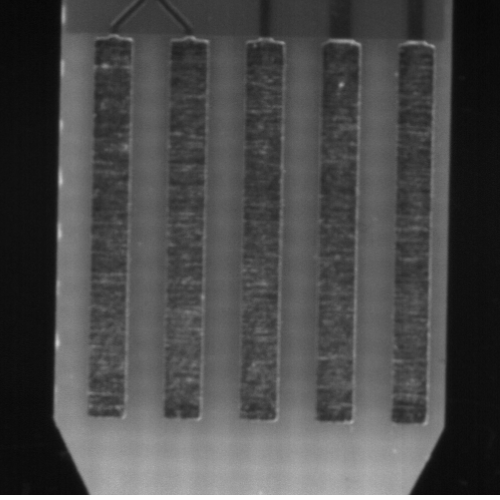

Autoencoder Corrected Output (G15.png):


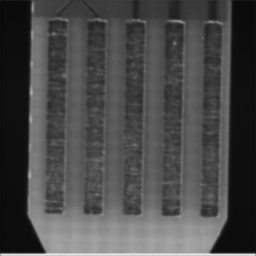

Processed G8.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G8.png
Original Image (G8.png):


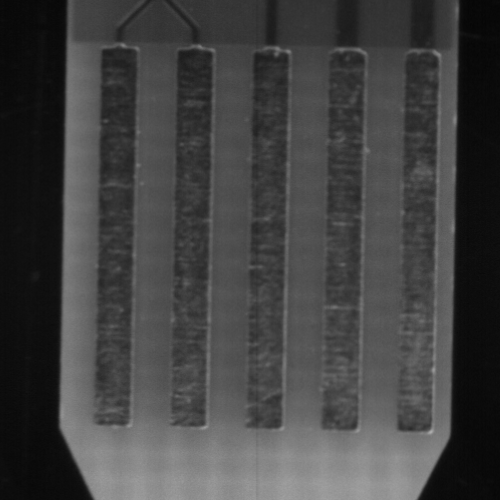

Autoencoder Corrected Output (G8.png):


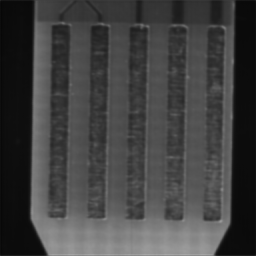

Processed G14.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G14.png
Original Image (G14.png):


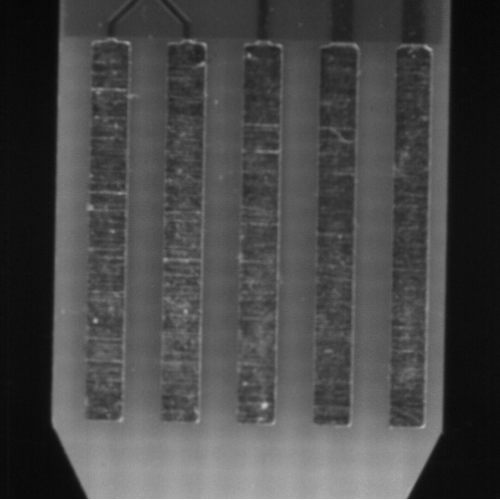

Autoencoder Corrected Output (G14.png):


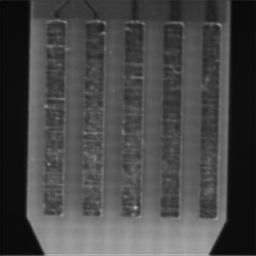

Processed G12.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G12.png
Original Image (G12.png):


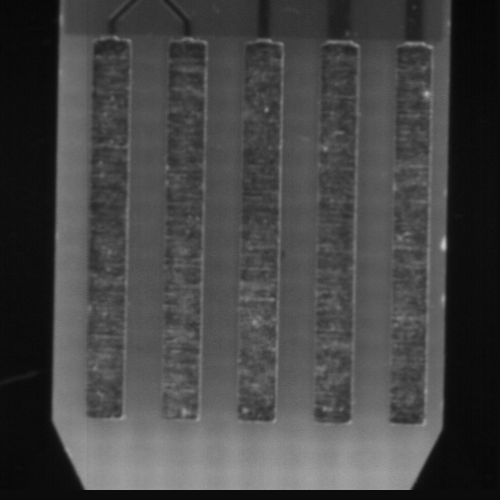

Autoencoder Corrected Output (G12.png):


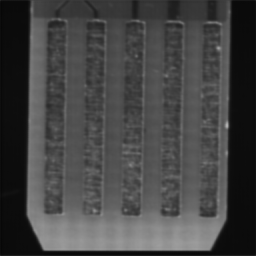

Processed G13.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G13.png
Original Image (G13.png):


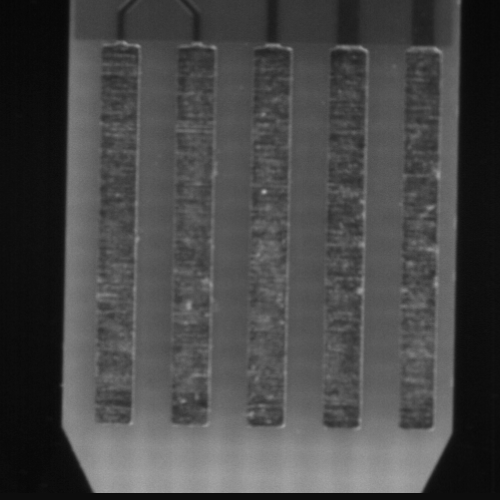

Autoencoder Corrected Output (G13.png):


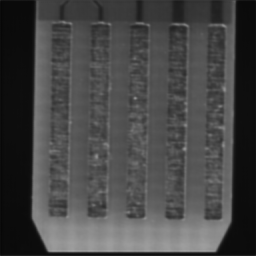

Processed G7.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G7.png
Original Image (G7.png):


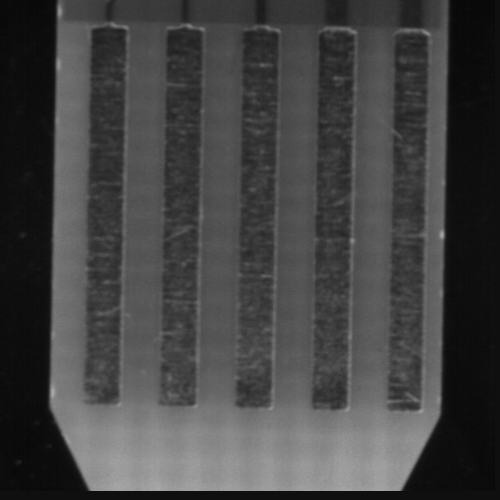

Autoencoder Corrected Output (G7.png):


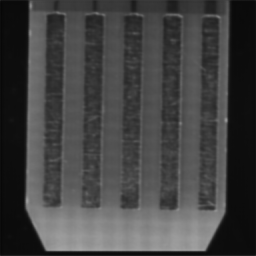

Processed G1.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G1.png
Original Image (G1.png):


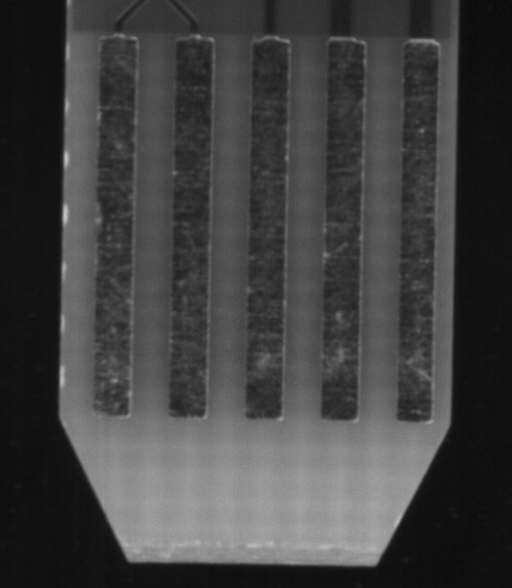

Autoencoder Corrected Output (G1.png):


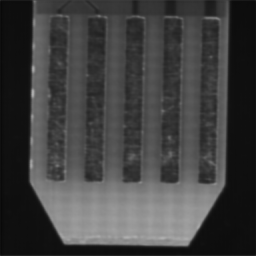

Processed G11.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G11.png
Original Image (G11.png):


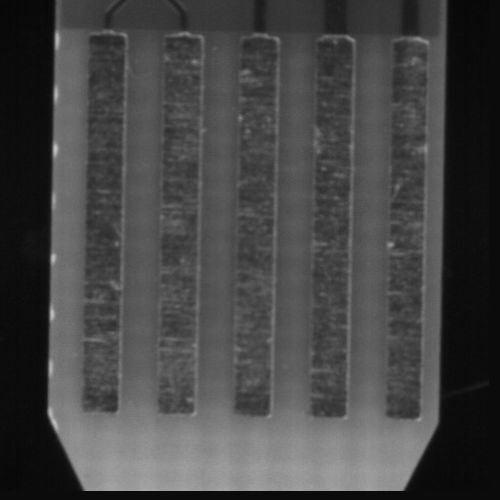

Autoencoder Corrected Output (G11.png):


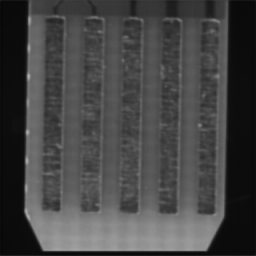

Processed G19.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G19.png
Original Image (G19.png):


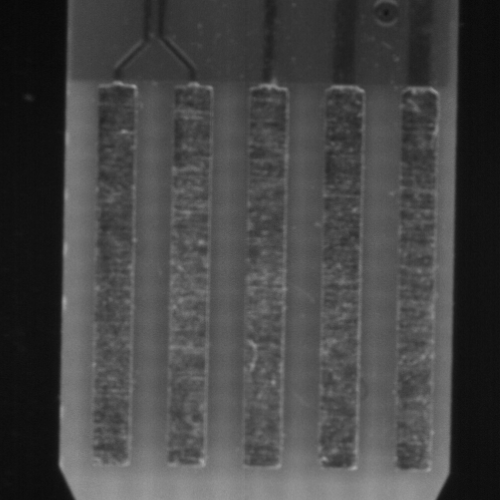

Autoencoder Corrected Output (G19.png):


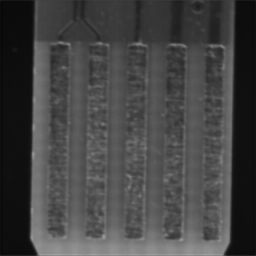

Processed G16.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G16.png
Original Image (G16.png):


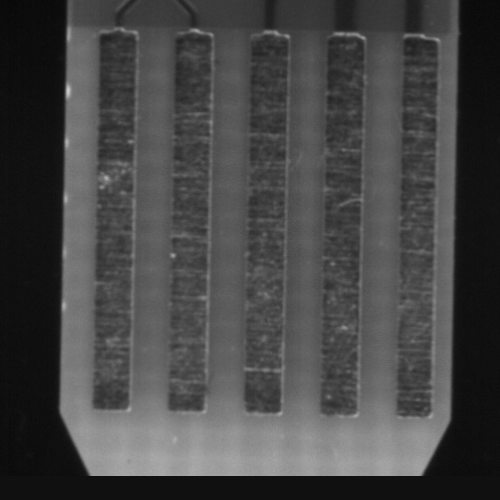

Autoencoder Corrected Output (G16.png):


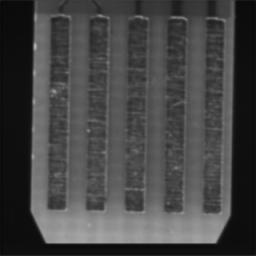

Processed G9.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G9.png
Original Image (G9.png):


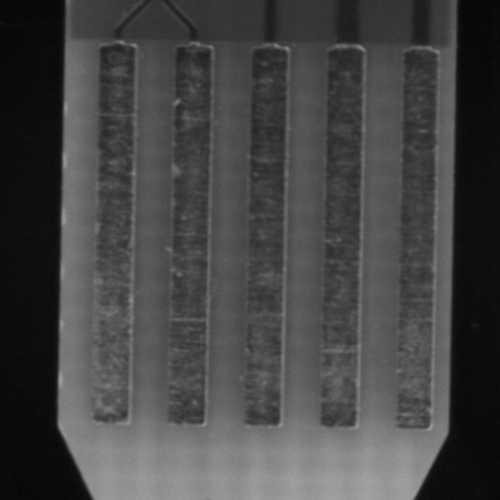

Autoencoder Corrected Output (G9.png):


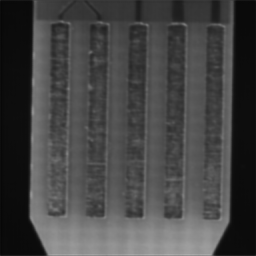

Processed G2.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G2.png
Original Image (G2.png):


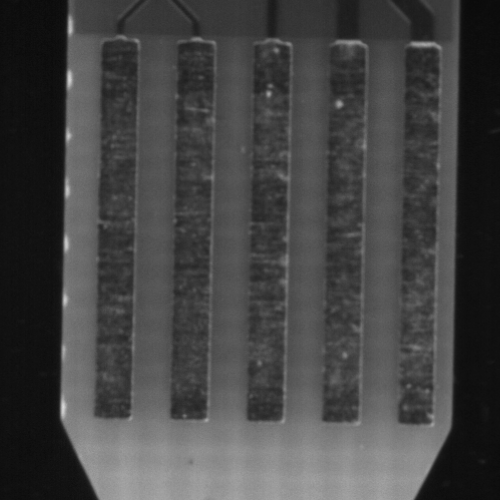

Autoencoder Corrected Output (G2.png):


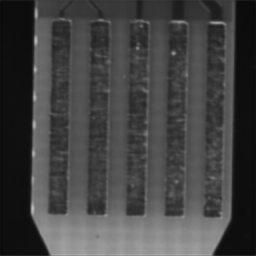

Processed G4.png and saved corrected image to /content/drive/MyDrive/good_images_new_folder/corrected_G4.png
Original Image (G4.png):


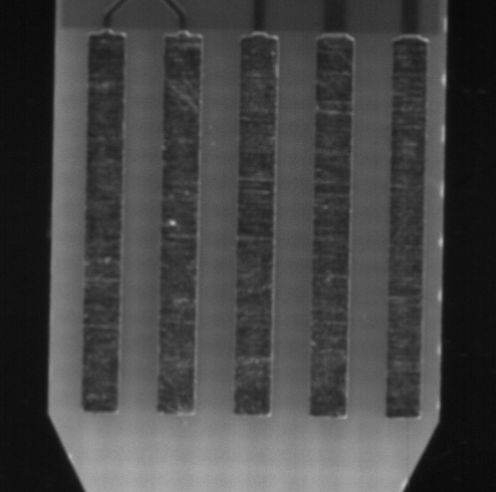

Autoencoder Corrected Output (G4.png):


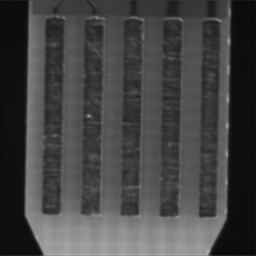

Autoencoder processing complete for all images.


In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as T
from PIL import Image
from google.colab.patches import cv2_imshow
from torch.utils.data import Dataset, DataLoader
from math import exp


# Corrected SSIM implementation
def gaussian(window_size, sigma):
    gauss = torch.Tensor([exp(-(x - window_size//2)**2/float(2*sigma**2)) for x in range(window_size)])
    return gauss/gauss.sum()

def create_window(window_size, channel=1):
    _1D_window = gaussian(window_size, 1.5).unsqueeze(1)
    _2D_window = _1D_window.mm(_1D_window.t()).float().unsqueeze(0).unsqueeze(0)
    window = _2D_window.expand(channel, 1, window_size, window_size).contiguous()
    return window

def ssim(img1, img2, window_size=11, window=None, size_average=True, full=False, val_range=None):
    if val_range is None:
        if torch.max(img1) > 128:
            max_val = 255
        else:
            max_val = 1
        if torch.min(img1) < -0.5:
            min_val = -1
        else:
            min_val = 0
        L = max_val - min_val
    else:
        L = val_range

    padd = window_size // 2
    (_, channel, height, width) = img1.size()
    if window is None:
        real_size = min(window_size, height, width)
        window = create_window(real_size, channel=channel).to(img1.device)

    mu1 = F.conv2d(img1, window, padding=padd, groups=channel)
    mu2 = F.conv2d(img2, window, padding=padd, groups=channel)
    mu1_sq = mu1.pow(2)
    mu2_sq = mu2.pow(2)
    mu1_mu2 = mu1 * mu2
    sigma1_sq = F.conv2d(img1 * img1, window, padding=padd, groups=channel) - mu1_sq
    sigma2_sq = F.conv2d(img2 * img2, window, padding=padd, groups=channel) - mu2_sq
    sigma12 = F.conv2d(img1 * img2, window, padding=padd, groups=channel) - mu1_mu2

    C1 = (0.01 * L) ** 2
    C2 = (0.03 * L) ** 2

    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))

    if size_average:
        return ssim_map.mean()
    else:
        return ssim_map.mean(1).mean(1).mean(1)


class ImageDataset(Dataset):
    def __init__(self, image_dir, image_size=(256, 256)):
        self.image_dir = image_dir
        self.files = sorted(os.listdir(image_dir))
        self.transform = T.Compose([
            T.Grayscale(),
            T.Resize(image_size),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filename = self.files[idx]
        image_path = os.path.join(self.image_dir, filename)
        image = self.transform(Image.open(image_path).convert("RGB"))
        return image, image


class LineAutoencoder(nn.Module):
    def __init__(self):
        super(LineAutoencoder, self).__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)  # 128x128
        self.enc2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)  # 64x64

        # Decoder
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)  # 128x128
        self.dec1 = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU())  # skip connection from enc2
        self.up2 = nn.ConvTranspose2d(32, 16, 2, stride=2) # 256x256
        self.dec2 = nn.Sequential(nn.Conv2d(48, 1, 3, padding=1), nn.Sigmoid()) # skip connection from enc1

    def forward(self, x):
        # Encoder
        x1 = self.enc1(x)         # 32x256x256
        p1 = self.pool1(x1)       # 32x128x128
        x2 = self.enc2(p1)        # 64x128x128
        p2 = self.pool2(x2)       # 64x64x64

        # Decoder
        up_x1 = self.up1(p2)      # 32x128x128
        cat1 = torch.cat([up_x1, p1], dim=1) # 64x128x128
        dec_x1 = self.dec1(cat1)  # 32x128x128

        up_x2 = self.up2(dec_x1)  # 16x256x256
        cat2 = torch.cat([up_x2, x1], dim=1) # 48x256x256
        output = self.dec2(cat2)    # 1x256x256
        return output

# Define the folder containing the input images
input_folder = '../data/raw/good_images' if os.path.exists('../data/raw/good_images') else ('data/raw/good_images' if os.path.exists('data/raw/good_images') else '/content/drive/MyDrive/Good Images')
autoencoder_output_folder = '../data/processed/corrected_good' if os.path.exists('../data/processed') else ('data/processed/corrected_good' if os.path.exists('data/processed') else '/content/drive/MyDrive/good_images_new_folder')
good_dir = "../data/raw/good_images" if os.path.exists("../data/raw/good_images") else ("data/raw/good_images" if os.path.exists("data/raw/good_images") else "/content/drive/MyDrive/Good Images")

# Create the updated output folder
os.makedirs(autoencoder_output_folder, exist_ok=True)

# Define the same transformations used for training the autoencoder
transform = T.Compose([
    T.Grayscale(),
    T.Resize((256, 256)), # Make sure this matches the training size
    T.ToTensor()
])


def hybrid_loss(pred, target):
    mse = nn.MSELoss()(pred, target)
    ssim_loss = 1 - ssim(pred, target) # Use the corrected local ssim function
    return 0.5 * mse + 0.5 * ssim_loss


dataset = ImageDataset(good_dir)
loader = DataLoader(dataset, batch_size=4, shuffle=True)

# 6. Train the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = LineAutoencoder().to(device)
criterion = hybrid_loss
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Training loop remains unchanged
epochs = 20
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for images, _ in loader:
        images = images.to(device)

        output = model(images)
        loss = criterion(output, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(loader):.6f}")



model.eval()
print(f"Applying autoencoder to images in: {input_folder}")

image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

for image_file in image_files:
    image_path = os.path.join(input_folder, image_file)
    autoencoder_output_path = os.path.join(autoencoder_output_folder, f"corrected_{image_file}")

    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        corrected_image_tensor = model(image_tensor)

    corrected_image_tensor = corrected_image_tensor.squeeze(0).cpu()
    corrected_image_numpy = corrected_image_tensor.mul(255).byte().numpy()
    corrected_image_numpy = np.transpose(corrected_image_numpy, (1, 2, 0))
    corrected_image_numpy = cv2.cvtColor(corrected_image_numpy, cv2.COLOR_GRAY2BGR)

    cv2.imwrite(autoencoder_output_path, corrected_image_numpy)

    print(f"Processed {image_file} and saved corrected image to {autoencoder_output_path}")

    print(f"Original Image ({image_file}):")
    cv2_imshow(cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR))

    print(f"Autoencoder Corrected Output ({image_file}):")
    cv2_imshow(corrected_image_numpy)

print("Autoencoder processing complete for all images.")


Processing: corrected_12.png


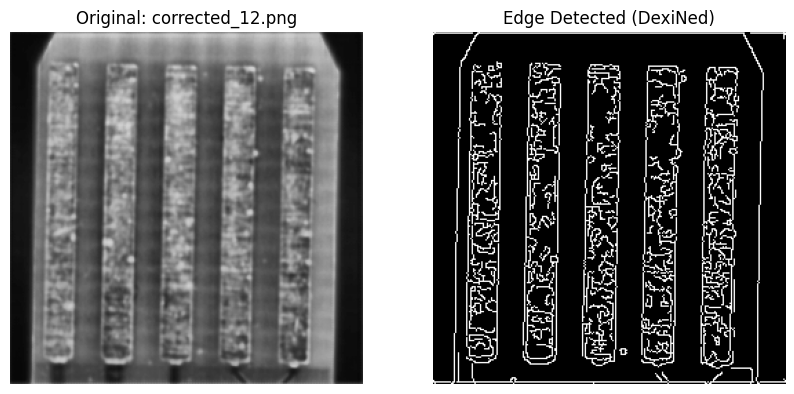

Processing: corrected_14.png


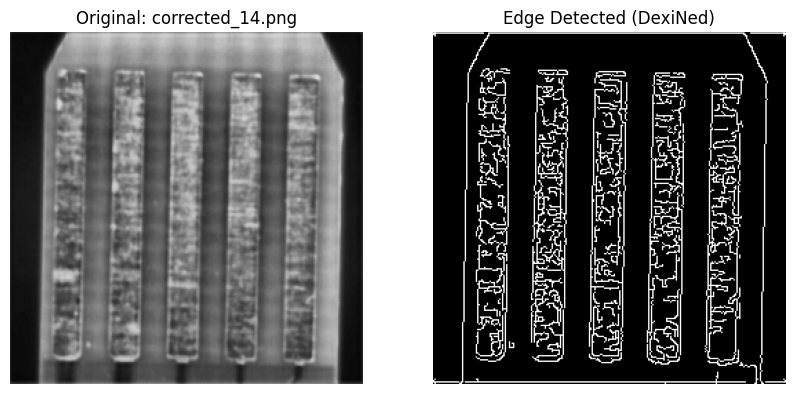

Processing: corrected_10.png


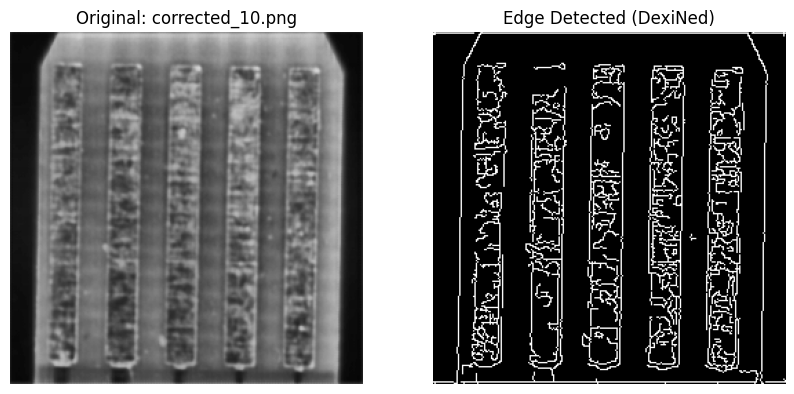

Processing: corrected_13.png


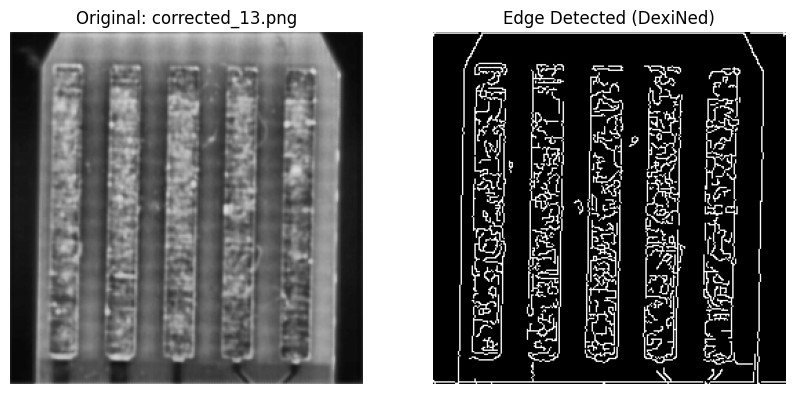

Processing: corrected_4.png


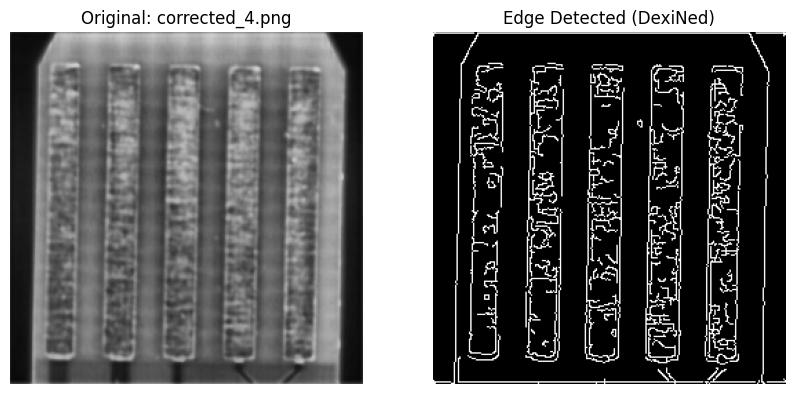

Processing: corrected_3.png


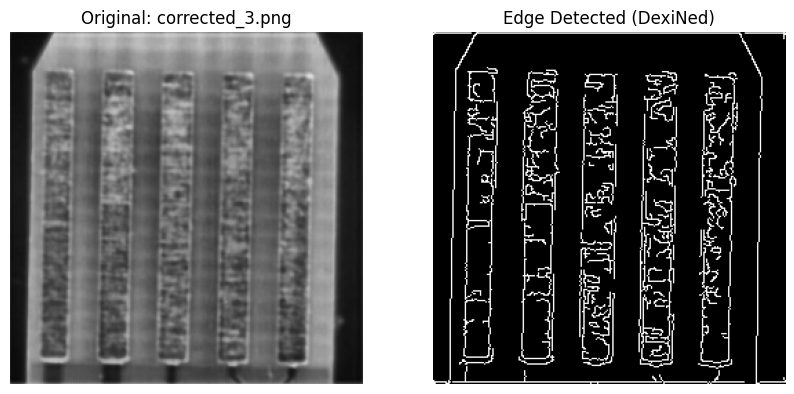

Processing: corrected_11.png


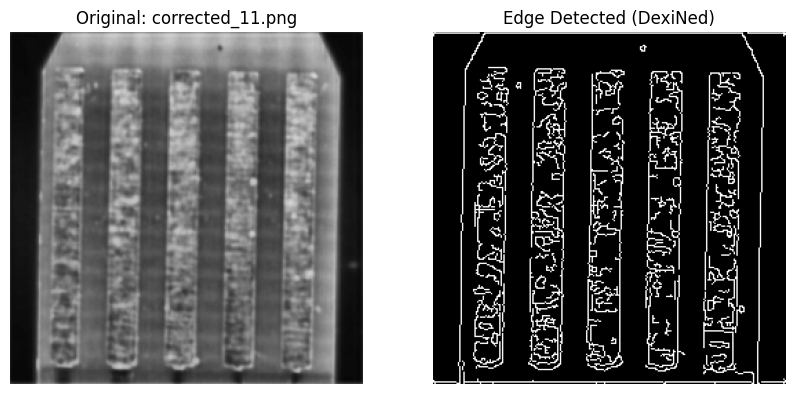

Processing: corrected_15.png


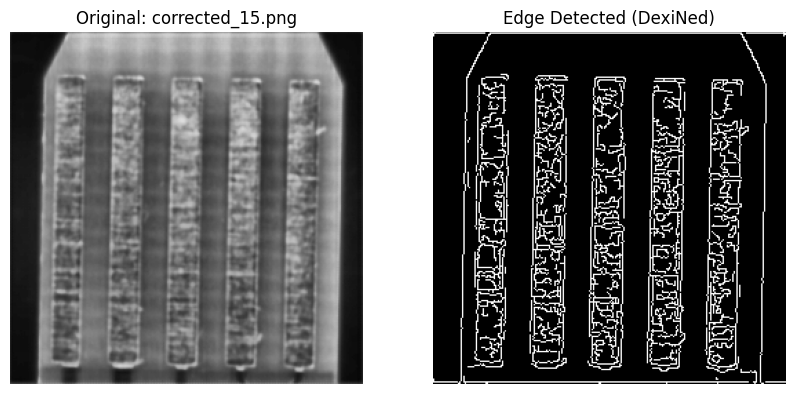

Processing: corrected_16.png


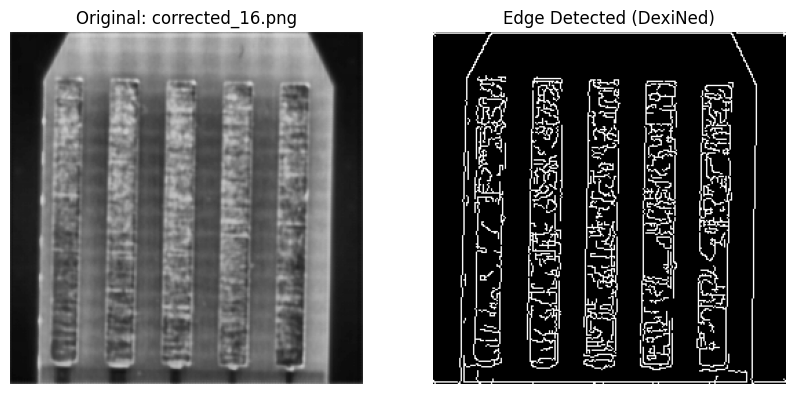

Processing: corrected_17.png


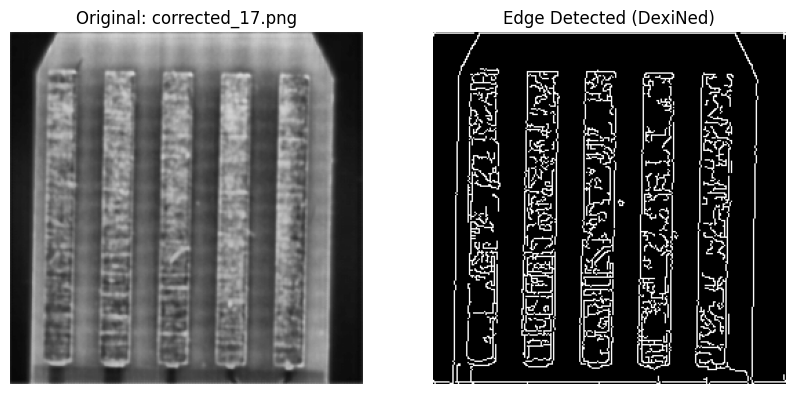

Processing: corrected_20.png


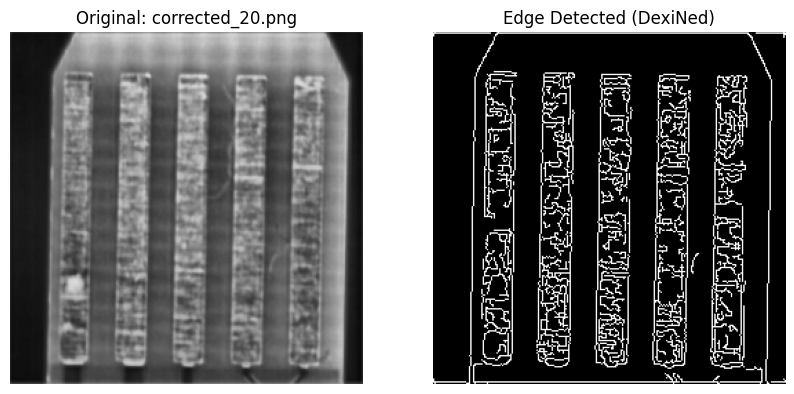

Processing: corrected_18.png


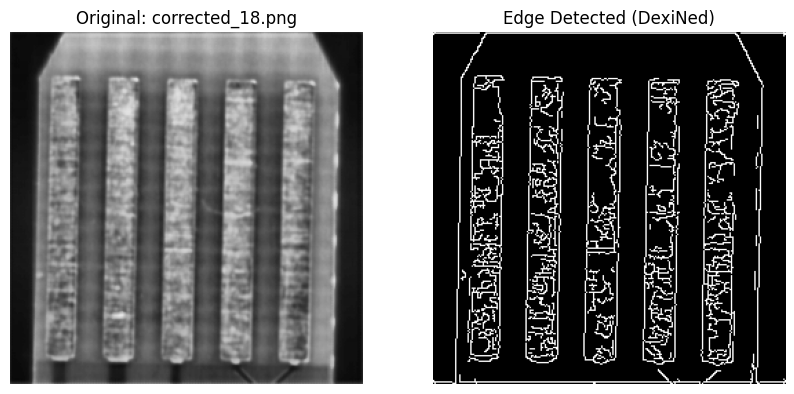

Processing: corrected_1.png


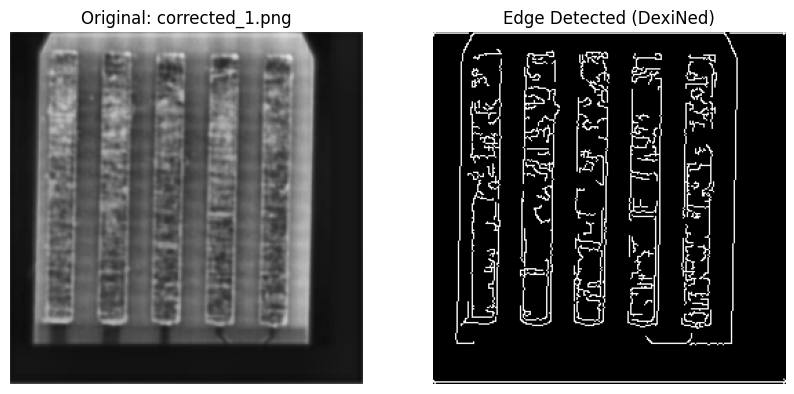

Processing: corrected_5.png


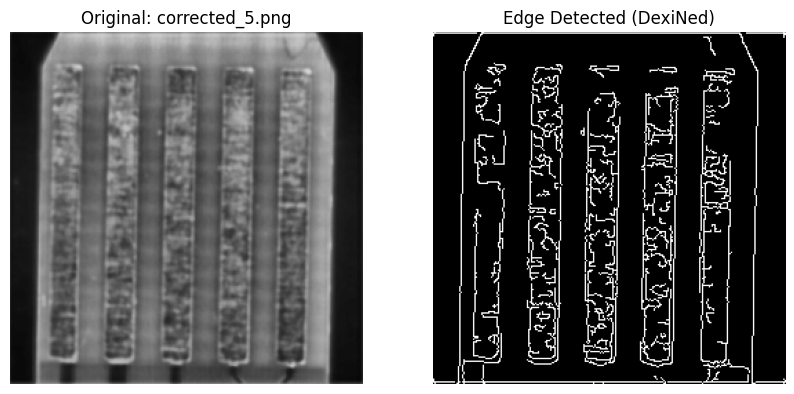

Processing: corrected_6.png


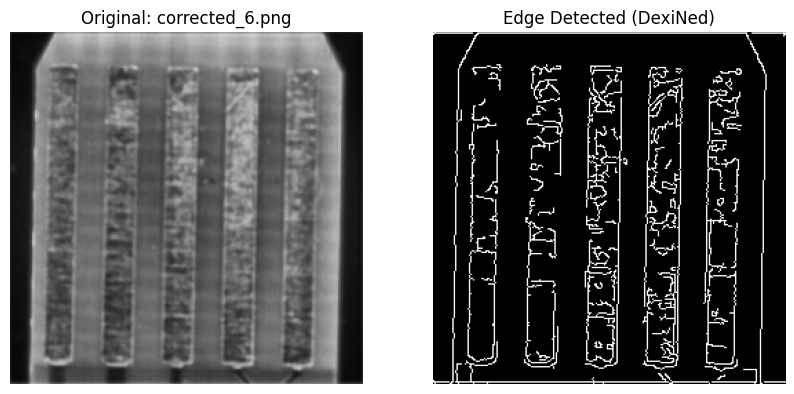

Processing: corrected_19.png


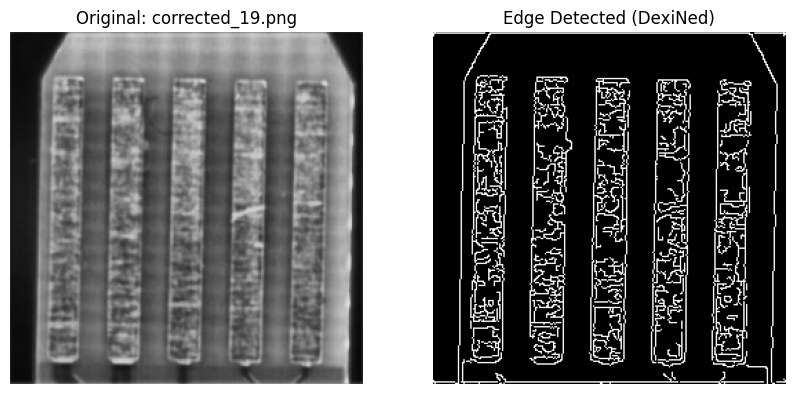

Processing: corrected_2.png


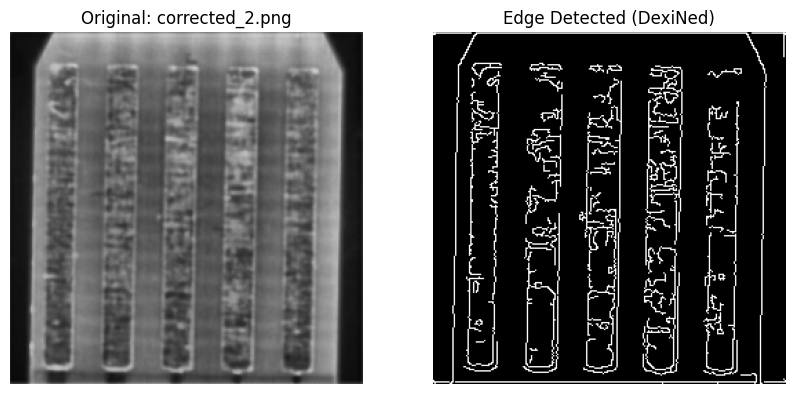

Processing: corrected_9.png


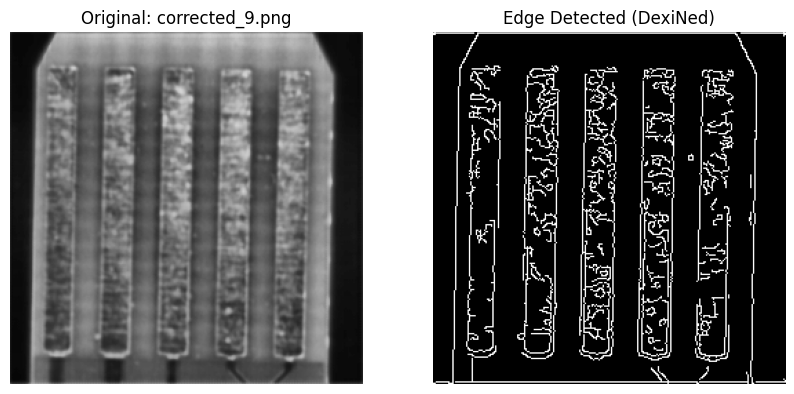

Processing: corrected_7.png


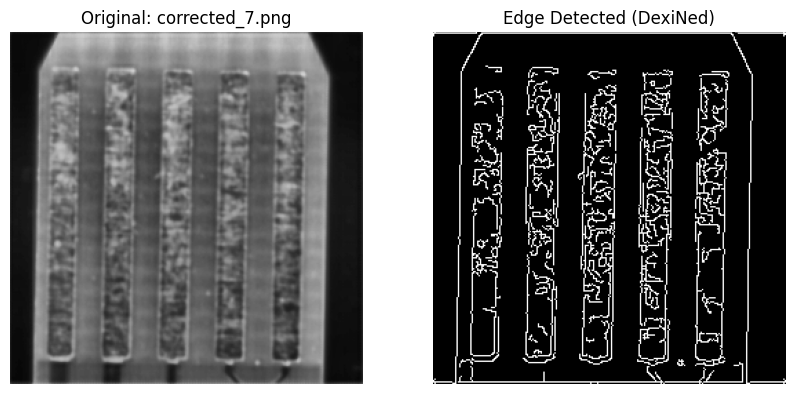

Processing: corrected_8.png


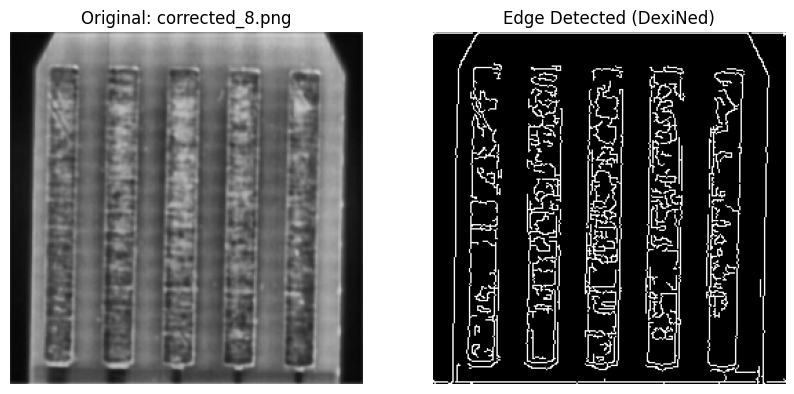

In [ ]:
# Step 2 (Updated): Process all images in a folder
import os

# Set the path to your image folder (change this path as needed)
folder_path = '../data/processed/corrected_bad' if os.path.exists('../data/processed/corrected_bad') else ('data/processed/corrected_bad' if os.path.exists('data/processed/corrected_bad') else '/content/drive/MyDrive/bad_images_new_folder')

# Create a list of all image files in the folder
image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))]

# Load your DexiNed model here (replace with your actual model loading code)
# dexiNed_model = load_dexined_model('path/to/your/model')

# Loop through and process each image
for image_file in image_files:
    image_path = os.path.join(folder_path, image_file)
    print(f'Processing: {image_file}')

    # Read the image
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)

    # Preprocess the image for your DexiNed model (replace with your preprocessing)
    # preprocessed_image = preprocess_for_dexined(image)

    # Get the edge-detected image from your model
    # edges = dexiNed_model.predict(preprocessed_image)

    # For demonstration, I'll create a dummy 'edges' image.
    # Replace this with your actual model's output.
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray_image, 100, 200)


    # Display the original and edge-detected images
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title(f'Original: {image_file}')
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title('Edge Detected (DexiNed)')
    plt.imshow(edges, cmap='gray')
    plt.axis('off')
    plt.show()

    # Display or save result as needed
    # cv2.imwrite(f"/content/output/{image_file}", edges)


In [ ]:
end_time = time.perf_counter()

In [ ]:
# Total time and per-image time
total_time = end_time - start_time
avg_time = total_time / len(image_files)

print(f"Total processing time: {total_time:.4f} seconds")
print(f"Average per image: {avg_time:.4f} seconds")

Total processing time: 208.1988 seconds
Average per image: 10.4099 seconds


In [ ]:
import os
import cv2
import numpy as np

def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 20 * np.log10(max_pixel / np.sqrt(mse))

# 🔹 Paths
input_folder = "../data/raw/bad_images" if os.path.exists("../data/raw/bad_images") else ("data/raw/bad_images" if os.path.exists("data/raw/bad_images") else "/content/drive/MyDrive/Bad Images")   # ground truth
output_folder = "../data/processed/corrected_bad" if os.path.exists("../data/processed/corrected_bad") else ("data/processed/corrected_bad" if os.path.exists("data/processed/corrected_bad") else "/content/drive/MyDrive/bad_images_new_folder")  # denoised

if not os.path.exists(input_folder):
    raise FileNotFoundError(f"⚠️ Input folder not found: {input_folder}")

image_files = [f for f in os.listdir(input_folder) if f.endswith(".png")]

for image_file in image_files:
    original_image_path = os.path.join(input_folder, image_file)

    # Possible denoised names
    candidates = [
        os.path.join(output_folder, f"corrected_{image_file}"),
        os.path.join(output_folder, image_file),
    ]

    denoised_image_path = next((c for c in candidates if os.path.exists(c)), None)
    if denoised_image_path is None:
        print(f"⚠️ Skipping {image_file}: no matching corrected file found")
        continue

    # Load grayscale
    original_image = cv2.imread(original_image_path, cv2.IMREAD_GRAYSCALE)
    denoised_image = cv2.imread(denoised_image_path, cv2.IMREAD_GRAYSCALE)

    if original_image is None or denoised_image is None:
        print(f"⚠️ Skipping {image_file}: could not read image data")
        continue

    # Resize if mismatch
    if denoised_image.shape != original_image.shape:
        denoised_image = cv2.resize(denoised_image, (original_image.shape[1], original_image.shape[0]))

    # Metrics
    mse = np.mean((original_image - denoised_image) ** 2)
    psnr = calculate_psnr(original_image, denoised_image)
    laplacian_var = cv2.Laplacian(denoised_image, cv2.CV_64F).var()

    print(f"Image: {image_file}")
    print(f"  MSE: {mse:.2f}")
    print(f"  PSNR: {psnr:.2f} dB")
    print(f"  Laplacian Variance (sharpness): {laplacian_var:.2f}")
    print("-" * 50)



Image: 12.png
  MSE: 89.16
  PSNR: 28.63 dB
  Laplacian Variance (sharpness): 29.16
--------------------------------------------------
Image: 14.png
  MSE: 88.14
  PSNR: 28.68 dB
  Laplacian Variance (sharpness): 30.06
--------------------------------------------------
Image: 10.png
  MSE: 86.69
  PSNR: 28.75 dB
  Laplacian Variance (sharpness): 27.35
--------------------------------------------------
Image: 15.png
  MSE: 85.05
  PSNR: 28.83 dB
  Laplacian Variance (sharpness): 31.43
--------------------------------------------------
Image: 11.png
  MSE: 88.16
  PSNR: 28.68 dB
  Laplacian Variance (sharpness): 24.78
--------------------------------------------------
Image: 17.png
  MSE: 88.61
  PSNR: 28.66 dB
  Laplacian Variance (sharpness): 30.99
--------------------------------------------------
Image: 16.png
  MSE: 83.50
  PSNR: 28.91 dB
  Laplacian Variance (sharpness): 27.87
--------------------------------------------------
Image: 3.png
  MSE: 85.09
  PSNR: 28.83 dB
  Laplacian 

In [ ]:
!pip install pytorch-ssim